Дано:
- дан класс K_Means кластеризации данных
Требуется:
- изменить способ задания начальных положений центров кластеров: разбросать случайным образом между(!) точек заданного обучающего множества dataset (определив разброс точек по всем координатам)
- изменить способ задания параметра tolerance: значение параметра должно равняться 1/10000 от минимального диапазона изменения признаков объектов (например, если один признак изменятся в диапазоне [100,200], а другой - [0.1,10], то tolerance = (10-0.1)/10000)
- дописать метод get_dist: пользователь должен иметь возможность использовать одну из 4 метрик при подсчете расстояний между объектами (евклидово расстояние, квадрат евклидова расстояния, расстояние городских кварталов, расстояние Чебышёва)
- написать метод get_predict: методом можно воспользоваться только после обучения модели (fitted == True), метод принимает двумерный массив объектов (могут быть точки не принадлежащие исходному обучающему множеству dataset), метод возвращает одномерный массив индексов соответствующих кластеров (по близости до центров кластеров)

Начальные центроиды:
[[-2.9726152  8.548556 ]
 [-9.351272  -7.677005 ]
 [-3.499734   8.4479885]]

Конечные центроиды:
[[ 4.747103   2.0105944]
 [-6.836401  -6.963878 ]
 [-2.7015967  8.973931 ]]


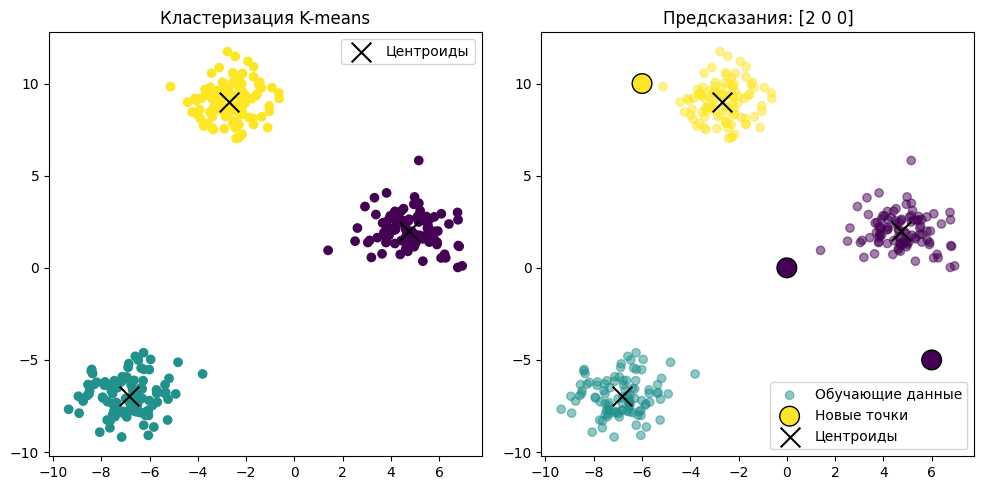


Tolerance: 0.001630580909418017


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
X, _ = make_blobs(n_samples=300, random_state=42)

class K_means():

    def __init__(self, dataset, n_clusters=3, metric='euclidean'):
        self.dataset = dataset
        self.n_clusters = n_clusters
        self.max_n_iter = 100
        self.tolerance = 1/10000 * min([dataset[:, i].max() - dataset[:, i].min()
                                        for i in range(dataset.shape[1])])
        self.fitted = False
        self.labels = np.array([], dtype='i')
        self.metric = metric

        indices = np.random.choice(len(dataset), n_clusters, replace=False)
        self.centroids = np.array([dataset[k] for k in indices], dtype='f')

    def get_dist(self, list1, list2):
        if self.metric == 'euclidean':
            return np.sqrt(sum([(i-j)**2 for i,j in zip(list1,list2)]))
        elif self.metric == 'sq_euclidean':
            return sum([(i-j)**2 for i,j in zip(list1,list2)])
        elif self.metric == 'manhattan':
            return sum([abs(i-j) for i,j in zip(list1,list2)])
        elif self.metric == 'chebyshev':
            return max([abs(i-j) for i,j in zip(list1,list2)])

    def distribute_data(self):
        self.labels = np.array([], dtype='i')
        for data in self.dataset:
            dist = np.array([self.get_dist(data, center)
                            for center in self.centroids])
            self.labels = np.append(self.labels, dist.argmin())

    def recalculate_centroids(self):
        for i in range(self.n_clusters):
            num = 0
            temp = np.empty(self.dataset[0].shape)
            for k, label in enumerate(self.labels):
                if label == i:
                    temp += self.dataset[k]
                    num += 1
            self.centroids[i] = temp / num

    def fit(self):
        iter = 1
        while iter < self.max_n_iter:
            prev_centroids = self.centroids.copy()
            self.distribute_data()
            self.recalculate_centroids()
            if max([self.get_dist(i, j) for i, j in zip(prev_centroids, self.centroids)]) \
            < self.tolerance:
                break
            iter += 1
        self.fitted = True

    def get_predict(self, data_array):
        if not self.fitted:
            raise Exception("Model not fitted yet. Call fit() first.")
        labels = np.array([], dtype='i')
        for data in data_array:
            dist = np.array([self.get_dist(data, center)
                            for center in self.centroids])
            labels = np.append(labels, dist.argmin())
        return labels


kmeans = K_means(X, n_clusters=3, metric='euclidean')

print("Начальные центроиды:")
print(kmeans.centroids)

kmeans.fit()

print("\nКонечные центроиды:")
print(kmeans.centroids)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=kmeans.labels, cmap='viridis')
plt.scatter(kmeans.centroids[:, 0], kmeans.centroids[:, 1],
            c='black', marker='x', s=200, label='Центроиды')
plt.title('Кластеризация K-means')
plt.legend()

new_points = np.array([[-6, 10], [6, -5], [0, 0]])
predictions = kmeans.get_predict(new_points)

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=kmeans.labels, cmap='viridis', alpha=0.5, label='Обучающие данные')
plt.scatter(new_points[:, 0], new_points[:, 1],
            c=predictions, cmap='viridis', marker='o', s=200, edgecolors='black', label='Новые точки')
plt.scatter(kmeans.centroids[:, 0], kmeans.centroids[:, 1],
            c='black', marker='x', s=200, label='Центроиды')
plt.title(f'Предсказания: {predictions}')
plt.legend()

plt.tight_layout()
plt.show()

print(f"\nTolerance: {kmeans.tolerance}")

Дано:
- гиперпараметр числа кластеров (n_clusters)
- гиперпараметр размытости (fuzzy)
- гиперпараметр отсечения (cut)
Требуется:
- реализовать обработку исключений, возникающих при делении на ноль
- дописать класс C_Means:

Центроиды:
[[ 4.28286207  1.99018535]
 [-2.56141606  8.71607181]
 [-6.81931577 -6.49331812]]

Метки кластеров (обучающие данные):
[2 0 1 0 2 0 1 0 0 1 1 2 2 1 1 2 2 1 2 2 1 2 2 1 1 1 0 2 2 2 2 0 0 2 1 1 1
 1 0 0 2 1 0 1 1 0 2 2 2 0 0 0 1 2 2 2 1 1 0 1 2 0 2 0 2 2 0 2 0 0 0 2 2 1
 0 2 0 2 0 0 1 0 1 2 1 1 1 0 1 0 0 0 1 0 1 1 1 0 2 1]

Количество точек в каждом кластере:
Кластер 0: 33 точек
Кластер 1: 34 точек
Кластер 2: 33 точек

Предсказания для новых точек: [-1  0  2]


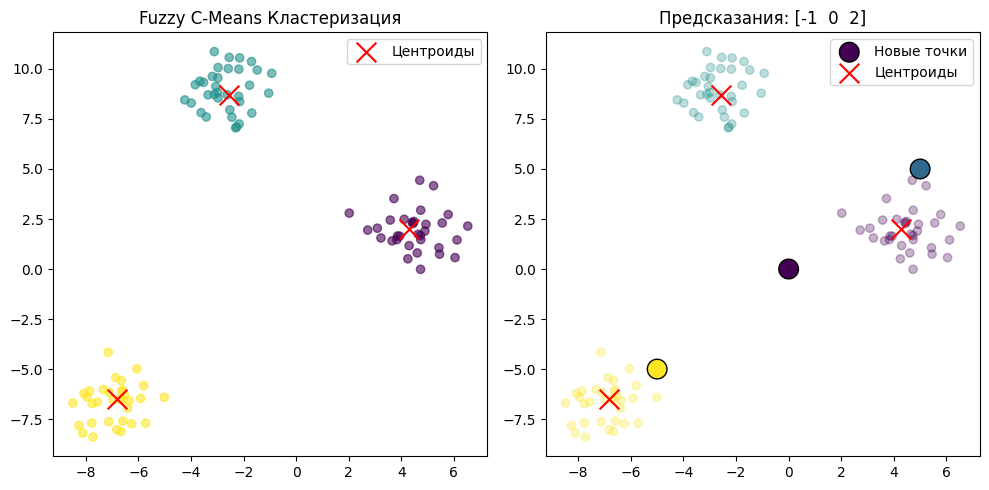

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

class C_Means():

    def __init__(self, dataset, n_clusters=3, fuzzy=2, cut=.9):
        self.dataset = dataset
        self.n_clusters = n_clusters
        self.fuzzy = fuzzy
        self.cut = cut
        self.max_n_iter = 100
        self.tolerance = 1e-2
        self.fitted = False
        self.labels = np.array([], dtype='i')
        indices = np.random.choice(self.dataset.shape[0], size=self.n_clusters, replace=False)
        self.centroids = self.dataset[indices] + 1
        self.U = np.array([], dtype='f')

    def get_dist(self, list1, list2):
        return np.sqrt(sum((i - j) ** 2 for i, j in zip(list1, list2)))

    def distribute_data(self):
        n_samples = self.dataset.shape[0]
        dist = np.array([[self.get_dist(self.dataset[i], self.centroids[j])
                         for j in range(self.n_clusters)] for i in range(n_samples)])

        dist = np.where(dist == 0, 1e-10, dist)

        U = (1 / dist) ** self.fuzzy

        row_sums = U.sum(axis=1)
        row_sums = np.where(row_sums == 0, 1e-10, row_sums)

        self.U = U / row_sums.reshape((n_samples, 1))

    def recalculate_centroids(self):
        for j in range(self.n_clusters):
            denom = self.U[:, j].sum()
            if denom == 0:
                denom = 1e-10

            numerator = np.zeros(self.dataset.shape[1])
            for i in range(self.dataset.shape[0]):
                numerator += self.U[i, j] * self.dataset[i]

            self.centroids[j] = numerator / denom

    def get_labels(self):
        n_samples = self.dataset.shape[0]
        self.labels = np.full(n_samples, -1, dtype='i')

        for i in range(n_samples):
            max_idx = np.argmax(self.U[i, :])

            if self.U[i, max_idx] >= self.cut:
                self.labels[i] = max_idx

    def fit(self):
        self.distribute_data()

        for iteration in range(self.max_n_iter):
            prev_U = self.U.copy()

            self.recalculate_centroids()

            self.distribute_data()

            diff = np.linalg.norm(self.U - prev_U)
            if diff < self.tolerance:
                break

        self.get_labels()
        self.fitted = True

    def predict(self, list2d):
        if not self.fitted:
            raise Exception("Model not fitted yet. Call fit() first.")

        labels = np.full(len(list2d), -1, dtype='i')

        for i, point in enumerate(list2d):
            dist = np.array([self.get_dist(point, centroid)
                            for centroid in self.centroids])

            dist = np.where(dist == 0, 1e-10, dist)

            U_new = (1 / dist) ** self.fuzzy
            row_sum = U_new.sum()
            if row_sum == 0:
                row_sum = 1e-10
            U_new = U_new / row_sum

            max_idx = np.argmax(U_new)
            if U_new[max_idx] >= self.cut:
                labels[i] = max_idx

        return labels

X, _ = make_blobs(n_samples=100, random_state=42)

fcm = C_Means(X, n_clusters=3, fuzzy=2, cut=0.8)

fcm.fit()

print("Центроиды:")
print(fcm.centroids)
print("\nМетки кластеров (обучающие данные):")
print(fcm.labels)
print("\nКоличество точек в каждом кластере:")
for i in range(fcm.n_clusters):
    print(f"Кластер {i}: {(fcm.labels == i).sum()} точек")

new_points = np.array([[0, 0], [5, 5], [-5, -5]])
predictions = fcm.predict(new_points)
print(f"\nПредсказания для новых точек: {predictions}")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=fcm.labels, cmap='viridis', alpha=0.6)
plt.scatter(fcm.centroids[:, 0], fcm.centroids[:, 1],
            c='red', marker='x', s=200, label='Центроиды')
plt.title('Fuzzy C-Means Кластеризация')
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=fcm.labels, cmap='viridis', alpha=0.3)
plt.scatter(new_points[:, 0], new_points[:, 1],
            c=predictions, cmap='viridis', marker='o', s=200,
            edgecolors='black', label='Новые точки')
plt.scatter(fcm.centroids[:, 0], fcm.centroids[:, 1],
            c='red', marker='x', s=200, label='Центроиды')
plt.title(f'Предсказания: {predictions}')
plt.legend()

plt.tight_layout()
plt.show()

Дано:
- класс DB_SCAN кластеризации данных

Требуется:
- реализовать эвристический метод побора гиперпараметра eps:

	1. Выберите значение гиперпараметра m. Обычно используются значения от 3 до 9, чем более неоднородный ожидается датасет, и чем больше уровень шума, тем большим следует взять m.

	2. Вычислите среднее расстояние по m ближайшим соседям для каждой точки. Т.е. если m=3, нужно выбрать трёх ближайших соседей, сложить расстояния до них и поделить на три.

	3. Отсортируйте полученные значения по возрастанию и выведите на экран.

	4. Гиперпараметр eps следует взять в полосе, где происходит самый сильный перегиб графика. Чем больше eps, тем больше получатся кластеры, и тем меньше их будет.

- проверить результат подбора параметра eps - показать результат кластеризации для заданного распределение точек при eps меньшим, равным и большим рекомендованного значения
- (не обязательно) попытаться автоматизировать подбор eps согласно эвристики без участия человека  (без построения и анализа графика)

Создание данных

Шаг 1: Подбор параметра eps
Средние расстояния по 5 ближайшим соседям (отсортированные):
Точка 0: 0.0279
Точка 1: 0.0304
Точка 2: 0.0312
Точка 3: 0.0321
Точка 4: 0.0335
Точка 5: 0.0359
Точка 6: 0.0368
Точка 7: 0.0371
Точка 8: 0.0373
Точка 9: 0.0373
Точка 10: 0.0376
Точка 11: 0.0377
Точка 12: 0.0381
Точка 13: 0.0385
Точка 14: 0.0393
Точка 15: 0.0398
Точка 16: 0.0402
Точка 17: 0.0402
Точка 18: 0.0408
Точка 19: 0.0413
Точка 20: 0.0417
Точка 21: 0.0420
Точка 22: 0.0422
Точка 23: 0.0424
Точка 24: 0.0424
Точка 25: 0.0429
Точка 26: 0.0444
Точка 27: 0.0449
Точка 28: 0.0455
Точка 29: 0.0456
Точка 30: 0.0461
Точка 31: 0.0463
Точка 32: 0.0467
Точка 33: 0.0470
Точка 34: 0.0472
Точка 35: 0.0474
Точка 36: 0.0476
Точка 37: 0.0476
Точка 38: 0.0477
Точка 39: 0.0478
Точка 40: 0.0479
Точка 41: 0.0482
Точка 42: 0.0489
Точка 43: 0.0491
Точка 44: 0.0492
Точка 45: 0.0493
Точка 46: 0.0494
Точка 47: 0.0494
Точка 48: 0.0497
Точка 49: 0.0503
Точка 50: 0.0504
Точка 51: 0.0509
Точка 52: 0.0509
Точ

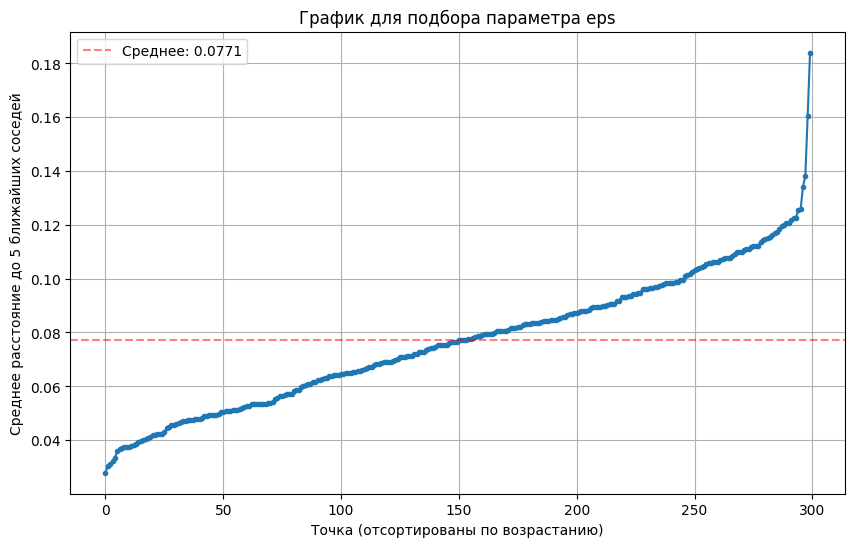


Рекомендация: выберите eps в полосе, где происходит самый сильный перегиб графика.
Чем больше eps, тем больше получатся кластеры, и тем меньше их будет.

Автоматический подбор eps:
Точка перегиба: индекс 297
Рекомендованное eps: 0.1380

Шаг 2: Проверка результатов кластеризации


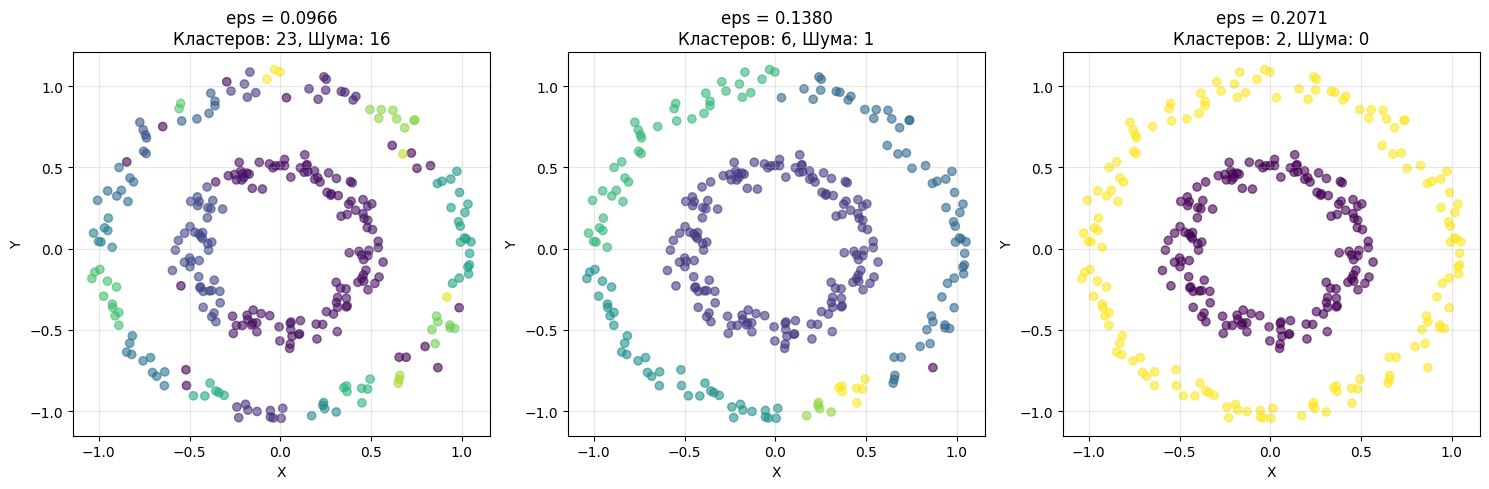


Результаты для eps = 0.0966 (меньше рекомендованного):
  Количество кластеров: 0
  Точек шума: 16

Результаты для eps = 0.1380 (рекомендованное):
  Количество кластеров: 6
  Точек шума: 1

Результаты для eps = 0.2071 (больше рекомендованного):
  Количество кластеров: 2
  Точек шума: 0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

class DB_SCAN():

    def __init__(self, dataset, eps=1, min_samples=1):
        self.dataset = dataset
        self.eps = eps
        self.min_samples = min_samples
        self.n_clusters = 0
        self.clusters = {0:[]}
        self.visited = []
        self.labels = np.array([], dtype='i')
        self.fitted = False

    def get_dist(self, list1, list2):
        return np.sqrt(sum((i-j)**2 for i,j in zip(list1,list2)))

    def get_neighbours(self, P):
        return {tuple(Q) for Q in self.dataset if self.get_dist(Q,P) < self.eps}

    def fit(self):
        for P in self.dataset:
            P = list(P)
            if P in self.visited: continue
            self.visited.append(P)
            neighbours = self.get_neighbours(P)
            if len(neighbours) < self.min_samples:
                self.clusters[0].append(P)
            else:
                self.expand_cluster(P)
        self.fitted = True

    def expand_cluster(self, P):
        self.n_clusters += 1
        self.clusters[self.n_clusters] = [P]
        neighbours = self.get_neighbours(P)
        while neighbours:
            Q = list(neighbours.pop())
            if Q in self.visited: continue
            self.visited.append(Q)
            self.clusters[self.n_clusters].append(Q)
            Q_neighbours = self.get_neighbours(Q)
            if len(Q_neighbours) > self.min_samples:
                neighbours = neighbours.union(Q_neighbours)
            if Q in self.clusters[0]: self.clusters[0].remove(Q)

    def get_labels(self):
        if not self.fitted: self.fit()
        labels = []
        for P in self.dataset:
            for i in range(self.n_clusters+1):
                if list(P) in self.clusters[i]:
                    labels.append(i)
                    break
        self.labels = np.array(labels, dtype='i')
        return self.labels

    def select_eps(self, m=5):

        n_samples = len(self.dataset)
        avg_distances = []

        for i, point in enumerate(self.dataset):
            distances = []
            for j, other_point in enumerate(self.dataset):
                if i != j:
                    dist = self.get_dist(point, other_point)
                    distances.append(dist)

            distances.sort()
            k = min(m, len(distances))
            avg_dist = sum(distances[:k]) / k
            avg_distances.append(avg_dist)

        avg_distances.sort()

        print(f"Средние расстояния по {m} ближайшим соседям (отсортированные):")
        for i, dist in enumerate(avg_distances):
            print(f"Точка {i}: {dist:.4f}")

        plt.figure(figsize=(10, 6))
        plt.plot(range(n_samples), avg_distances, marker='o', linestyle='-', markersize=3)
        plt.xlabel('Точка (отсортированы по возрастанию)')
        plt.ylabel(f'Среднее расстояние до {m} ближайших соседей')
        plt.title('График для подбора параметра eps')
        plt.grid(True)
        plt.axhline(y=avg_distances[n_samples//2], color='r', linestyle='--', alpha=0.5,
                   label=f'Среднее: {avg_distances[n_samples//2]:.4f}')
        plt.legend()
        plt.show()

        print("\nРекомендация: выберите eps в полосе, где происходит самый сильный перегиб графика.")
        print("Чем больше eps, тем больше получатся кластеры, и тем меньше их будет.")

        return avg_distances

    def find_optimal_eps(self, m=5):
        n_samples = len(self.dataset)
        avg_distances = []

        for i, point in enumerate(self.dataset):
            distances = []
            for j, other_point in enumerate(self.dataset):
                if i != j:
                    dist = self.get_dist(point, other_point)
                    distances.append(dist)

            distances.sort()
            k = min(m, len(distances))
            avg_dist = sum(distances[:k]) / k
            avg_distances.append(avg_dist)

        avg_distances.sort()

        derivatives = np.diff(avg_distances)

        second_derivatives = np.diff(derivatives)
        elbow_idx = np.argmax(second_derivatives) + 1

        optimal_eps = avg_distances[elbow_idx]

        print(f"\nАвтоматический подбор eps:")
        print(f"Точка перегиба: индекс {elbow_idx}")
        print(f"Рекомендованное eps: {optimal_eps:.4f}")

        return optimal_eps


print("=" * 60)
print("Создание данных")
print("=" * 60)

X, _ = make_circles(n_samples=300, factor=.5, noise=.05)

print("\n" + "=" * 60)
print("Шаг 1: Подбор параметра eps")
print("=" * 60)

dbscan = DB_SCAN(X, eps=1, min_samples=3)
avg_distances = dbscan.select_eps(m=5)

optimal_eps = dbscan.find_optimal_eps(m=5)

print("\n" + "=" * 60)
print("Шаг 2: Проверка результатов кластеризации")
print("=" * 60)

eps_values = [optimal_eps * 0.7, optimal_eps, optimal_eps * 1.5]
labels_list = []

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, eps in enumerate(eps_values):
    dbscan_test = DB_SCAN(X, eps=eps, min_samples=3)
    labels = dbscan_test.get_labels()
    labels_list.append(labels)

    axes[i].scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', alpha=0.6)
    axes[i].set_title(f'eps = {eps:.4f}\nКластеров: {dbscan_test.n_clusters}, Шума: {(labels == 0).sum()}')
    axes[i].set_xlabel('X')
    axes[i].set_ylabel('Y')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nРезультаты для eps = {eps_values[0]:.4f} (меньше рекомендованного):")
print(f"  Количество кластеров: {dbscan.n_clusters}")
print(f"  Точек шума: {(labels_list[0] == 0).sum()}")

dbscan_test = DB_SCAN(X, eps=eps_values[1], min_samples=3)
labels_test = dbscan_test.get_labels()
print(f"\nРезультаты для eps = {eps_values[1]:.4f} (рекомендованное):")
print(f"  Количество кластеров: {dbscan_test.n_clusters}")
print(f"  Точек шума: {(labels_test == 0).sum()}")

dbscan_test = DB_SCAN(X, eps=eps_values[2], min_samples=3)
labels_test = dbscan_test.get_labels()
print(f"\nРезультаты для eps = {eps_values[2]:.4f} (больше рекомендованного):")
print(f"  Количество кластеров: {dbscan_test.n_clusters}")
print(f"  Точек шума: {(labels_test == 0).sum()}")
